# Prepare samples of OpenAI Moderations Outputs for manual annotation 

1. Random sample of nearly 50,000 records from moderated instances --> annotate a balanced subsample 
2. Random sample of nearly 50,000 from all instances --> annotate 1500 instances

In [3]:
from os.path import join
from hate_speech.hs_helpers import parse_moderation_batch_output, parse_moderation_batch_input
import pandas as pd

## Moderated instances sample

In [2]:
path = join("openai_output", "batch_moderated_servers_sample.jsonl")
df = parse_moderation_batch_output(path)

In [3]:
df.head(3)

,custom_id,status_code,request_id,model,flagged,categories.harassment,categories.harassment/threatening,categories.sexual,categories.hate,categories.hate/threatening,...,category_applied_input_types.hate,category_applied_input_types.hate/threatening,category_applied_input_types.illicit,category_applied_input_types.illicit/violent,category_applied_input_types.self-harm/intent,category_applied_input_types.self-harm/instructions,category_applied_input_types.self-harm,category_applied_input_types.sexual/minors,category_applied_input_types.violence,category_applied_input_types.violence/graphic
0,AZJecjd6VVktcAiPgm,200,0c4436ea6ca0dcd8a0f634465c7dcc61,omni-moderation-2024-09-26,False,False,False,False,False,False,...,[text],[text],[text],[text],[text],[text],[text],[text],[text],[text]
1,111456473256300072,200,c808cffeb367ab217132c00ab9460aa1,omni-moderation-2024-09-26,False,False,False,False,False,False,...,[text],[text],[text],[text],[text],[text],[text],[text],[text],[text]
2,AYAuuYQoIb1CDsiVhw,200,6694a03caa801f1cb6f1e24bc956f75a,omni-moderation-2024-09-26,False,False,False,False,False,False,...,[text],[text],[text],[text],[text],[text],[text],[text],[text],[text]


In [4]:
len(df)

45338

<Axes: >

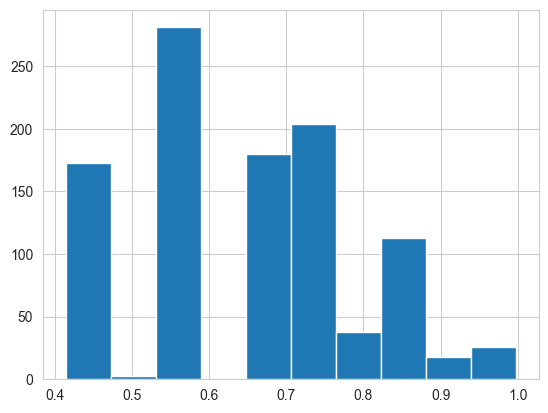

In [5]:
df[df["categories.hate"]==True]["category_scores.hate"].hist()

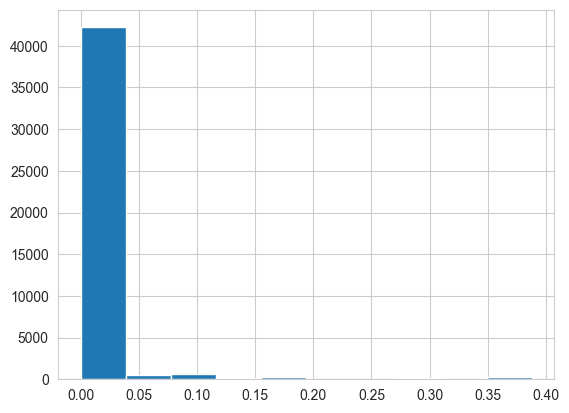

In [6]:
# not hate
df[df["categories.hate"]==False]["category_scores.hate"].hist();

### Merge with original data to get texts

In [7]:
original_data = pd.read_csv(join("openai_input", "sample_moderated_instances.csv"))

In [8]:
original_data.drop_duplicates(subset=["id"], inplace=True)

In [9]:
len(original_data)

49969

In [10]:
len(df)

45338

In [11]:
set(df.custom_id.unique()).issubset(set(original_data.id.unique()))

True

In [12]:
df = df.merge(original_data[["id", "url_cleaned", "content_cleaned"]], left_on="custom_id", right_on="id", how="left")

In [13]:
df.sample(3)

,custom_id,status_code,request_id,model,flagged,categories.harassment,categories.harassment/threatening,categories.sexual,categories.hate,categories.hate/threatening,...,category_applied_input_types.illicit/violent,category_applied_input_types.self-harm/intent,category_applied_input_types.self-harm/instructions,category_applied_input_types.self-harm,category_applied_input_types.sexual/minors,category_applied_input_types.violence,category_applied_input_types.violence/graphic,id,url_cleaned,content_cleaned
9482,109744890686799309,200,8114c816945186fc9a67262a21b31e9b,omni-moderation-2024-09-26,False,False,False,False,False,False,...,[text],[text],[text],[text],[text],[text],[text],109744890686799309,animalliberation.social/@andrewrihana421/10974...,Trading Carriesr riskTrader beast📊trading tips...
8122,109794715308136653,200,ce2aeccf0f853751bd1e51a379999fc8,omni-moderation-2024-09-26,False,False,False,False,False,False,...,[text],[text],[text],[text],[text],[text],[text],109794715308136653,md.ilyamikcoder.com/@Houl/109794715308136653,Discord is adding themes but... for nitro user...
18502,ATleyOhm1pmdskGIDo,200,8d1a7dffb5d636e3f344601249b1ee85,omni-moderation-2024-09-26,True,True,False,False,True,False,...,[text],[text],[text],[text],[text],[text],[text],ATleyOhm1pmdskGIDo,tuusin.misono-ya.info,"""i'm in the bottom of my class because i can't..."


In [14]:
len(df)

45338

### Export sample to CSV

For manual annotation

In [16]:
out_path = join("openai_output", "moderated_servers_sample_for_manual_annotation.csv")

In [19]:
df_1 = df[df["categories.hate"]==True].copy()
df_0 = df[df["categories.hate"]==False].sample(n=len(df_1), random_state=42).copy()
df_balanced = pd.concat([df_1, df_0]).reset_index(drop=True)
df_balanced[["custom_id", "url_cleaned", "content_cleaned", "categories.hate", "category_scores.hate"]].to_csv(out_path, index=False)

## Random sample

In [17]:
path = join("openai_output", "batch_random_sample.jsonl")
df = parse_moderation_batch_output(path)

In [18]:
len(df)

49000

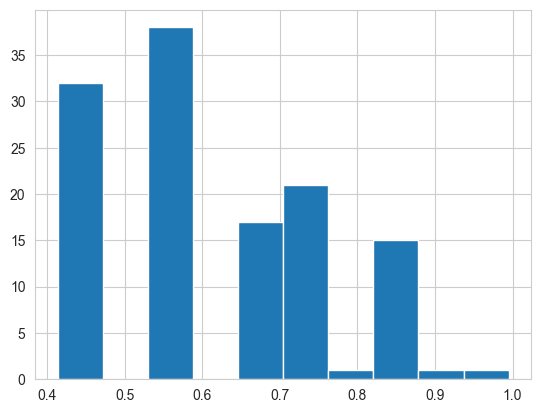

In [19]:
# hate
df[df["categories.hate"]==True]["category_scores.hate"].hist();

<Axes: >

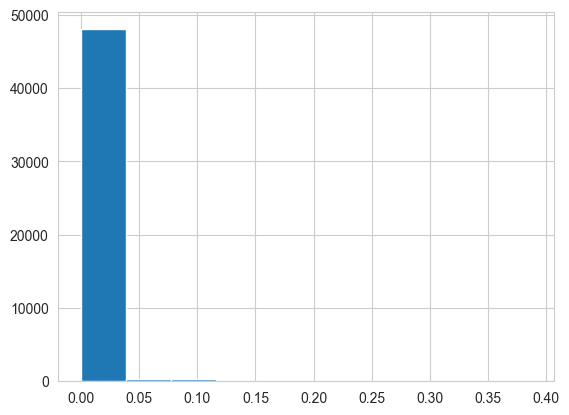

In [20]:
# not hate
df[df["categories.hate"]==False]["category_scores.hate"].hist()

### Merge with original data to get texts

In [21]:
original_data = parse_moderation_batch_input(join("openai_input", "100.jsonl"))

In [23]:
len(original_data)

49000

In [24]:
set(df.custom_id.unique()).issubset(set(original_data.custom_id.unique()))

True

In [25]:
df = df.merge(original_data[["custom_id", "input"]], on="custom_id", how="left")

In [26]:
len(df)

49000

### Export sample to CSV

In [28]:
out_path_annotation = join("openai_output", "random_sample_for_manual_annotation.csv")
out_path_ground_truth = join("openai_output", "random_sample_for_manual_annotation_with_ground_truth.csv")

In [29]:
df_sample = df.sample(n=1500, random_state=42).copy()

In [30]:
# df_sample[["custom_id", "input"]].to_csv(out_path_annotation, index=False)

In [31]:
df_sample.to_csv(out_path_ground_truth, index=False)